In [72]:
#1. Mount the Google Drive
from google.colab import drive
drive.mount('/content/drive')

#2. Import standard astronomy libraries
import matplotlib.pyplot as plt
import numpy as np
import glob
from astropy.io import fits
from astropy.utils.data import download_file
from astropy.visualization import astropy_mpl_style
from astropy.visualization import ZScaleInterval
from scipy.optimize import curve_fit
import os

#3. For animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

#4. Suppress Astropy FITS header padding warnings
import warnings
from astropy.utils.exceptions import AstropyUserWarning
warnings.filterwarnings('ignore', category=AstropyUserWarning)

print("Libraries imported successfully")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully


In [73]:
# Functions
def display_fits(fits_input, title=None, cmap='gray'):
    """
    Display a FITS image using matplotlib with optimal astronomical scaling.

    Parameters:
    - fits_input (str or numpy.ndarray): FITS file path or 2D image array.
    - title (str): Custom plot title (optional).
    - cmap (str): Matplotlib colormap (default: 'gray').
    """
    # 1. Load data if a filepath is provided
    if isinstance(fits_input, str):
        data = fits.getdata(fits_input)
        if title is None:
            title = fits_input.split('/')[-1]
    else:
        data = fits_input
        if title is None:
            title = "FITS Image"

    # 2. Calculate automatic contrast limits (ZScale)
    interval = ZScaleInterval()
    vmin, vmax = interval.get_limits(data)

    # 3. Plot image
    plt.figure(figsize=(7, 6))
    im = plt.imshow(data, origin='lower', cmap=cmap, vmin=np.percentile(data,5), vmax=np.percentile(data,95))
    plt.colorbar(im, label='Counts (ADU)')

    plt.title(title)
    plt.xlabel('X (pixels)')
    plt.ylabel('Y (pixels)')
    plt.tight_layout()
    plt.show()

def animate_fits_series(file_list, interval_ms=200, title_prefix="Frame"):
    """
    Display a list of FITS files as an animation in Jupyter Notebook.
    """
    if not file_list:
        raise ValueError("The file list is empty.")

    # 1. Load data from all FITS files
    frames = [fits.getdata(f).astype('float32') for f in file_list]

    # 2. Compute contrast limits (ZScale) from the first frame
    zscale = ZScaleInterval()
    vmin, vmax = zscale.get_limits(frames[0])

    # 3. Setup Matplotlib plot with FIRST frame (frames)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(frames[0], origin='lower', cmap='gray', vmin=np.percentile(frames[0],5), vmax=np.percentile(frames[0],95))
    cbar = plt.colorbar(im, ax=ax, label='Counts (ADU)')

    first_fname = os.path.basename(file_list[0])
    title_text = ax.set_title(f"{title_prefix} 1/{len(frames)}: {first_fname}")
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
    plt.tight_layout()

    # 4. Update function for FuncAnimation
    def update(frame_idx):
        im.set_data(frames[frame_idx])
        fname = os.path.basename(file_list[frame_idx])
        title_text.set_text(f"{title_prefix} {frame_idx + 1}/{len(frames)}: {fname}")
        return [im, title_text]

    # 5. Build animation
    anim = FuncAnimation(
        fig,
        update,
        frames=len(frames),
        interval=interval_ms,
        blit=True
    )

    plt.close(fig)  # Prevent duplicate static plot display

    return HTML(anim.to_jshtml())


#Directory

In [74]:
# Setup directory paths
base_dir = '/content/drive/MyDrive/S3 - ISYA/Hi-Res Spect Data/'
output_dir = os.path.join(base_dir, 'Reduced-Python-new')
os.makedirs(output_dir, exist_ok=True)

# File discovery by folder
dark_files = sorted(glob.glob(os.path.join(base_dir, 'Dark_*.fit')))
flat_files = sorted(glob.glob(os.path.join(base_dir, 'Flat_*.fit')))
saturn_files = sorted(glob.glob(os.path.join(base_dir, 'Saturn_Object_60s_*.fit')))
bias_files = sorted(glob.glob(os.path.join(base_dir, 'Bias_*.fit')))

#1. Quick Look

In [75]:
#animate_fits_series(saturn_files, interval_ms=200)

In [76]:
#animate_fits_series(flat_files, interval_ms=200)

#2. Master Flat, Dark, Bias

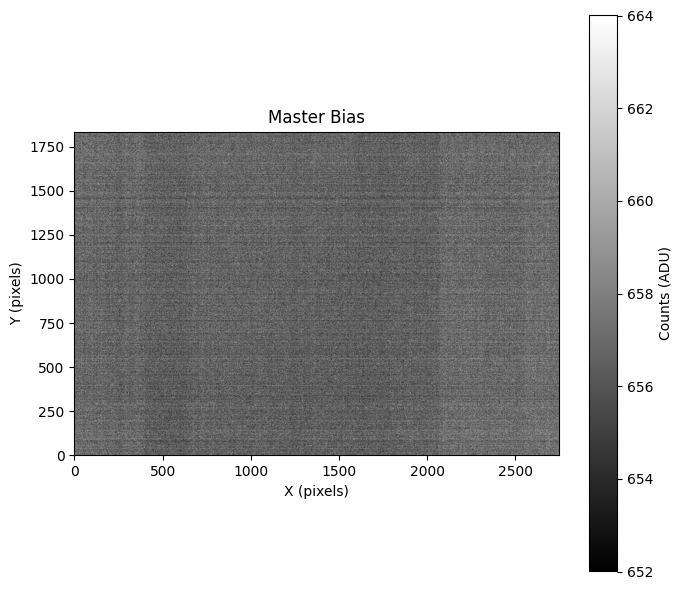

In [77]:
#Master Bias
bias_stack = [fits.getdata(f).astype(np.float32) for f in bias_files]
master_bias = np.median(bias_stack, axis=0)
fits.writeto(os.path.join(output_dir, 'master_bias.fits'), master_bias, overwrite=True)

display_fits(os.path.join(output_dir, 'master_bias.fits'), title='Master Bias')

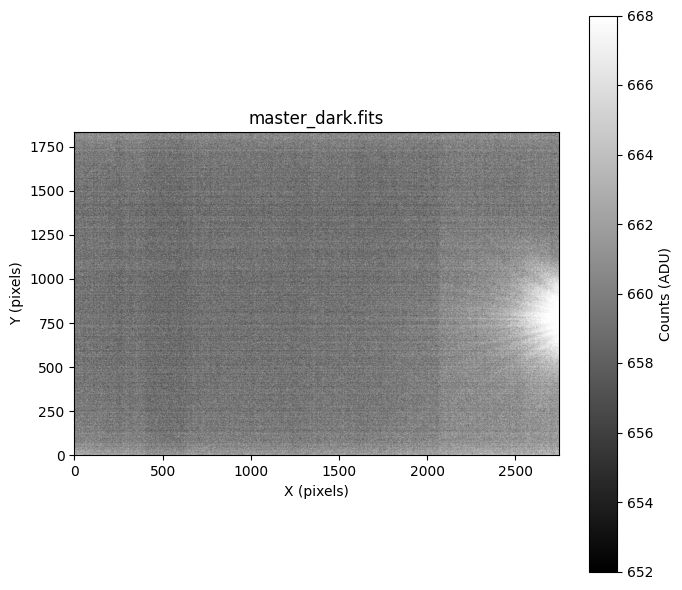

In [78]:
#Master Dark
dark_stack = [fits.getdata(f).astype(np.float32) for f in dark_files]
master_dark = np.median(dark_stack, axis=0)
fits.writeto(os.path.join(output_dir, 'master_dark.fits'), master_dark, overwrite=True)

display_fits(os.path.join(output_dir, 'master_dark.fits'))

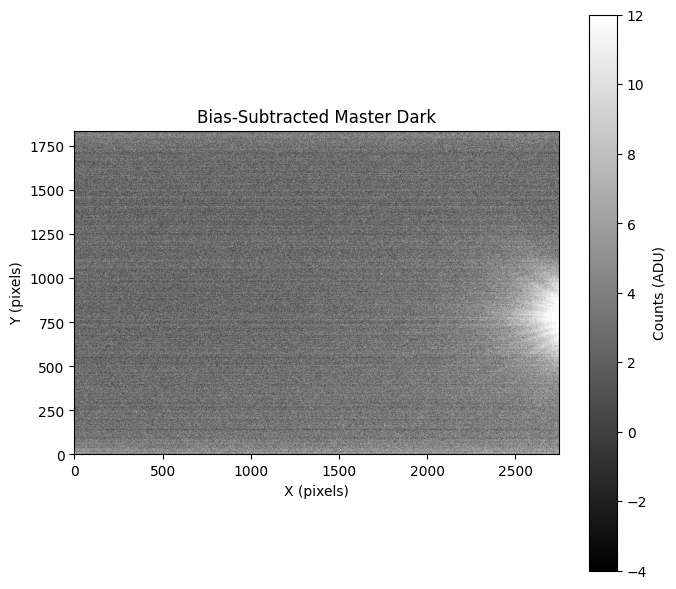

In [79]:
dark_stack_corrected = [fits.getdata(f).astype(np.float32) - master_bias for f in dark_files]
master_dark_corrected = np.median(dark_stack_corrected, axis=0)
fits.writeto(os.path.join(output_dir, 'master_dark_corrected.fits'), master_dark_corrected, overwrite=True)

display_fits(os.path.join(output_dir, 'master_dark_corrected.fits'), title='Bias-Subtracted Master Dark')

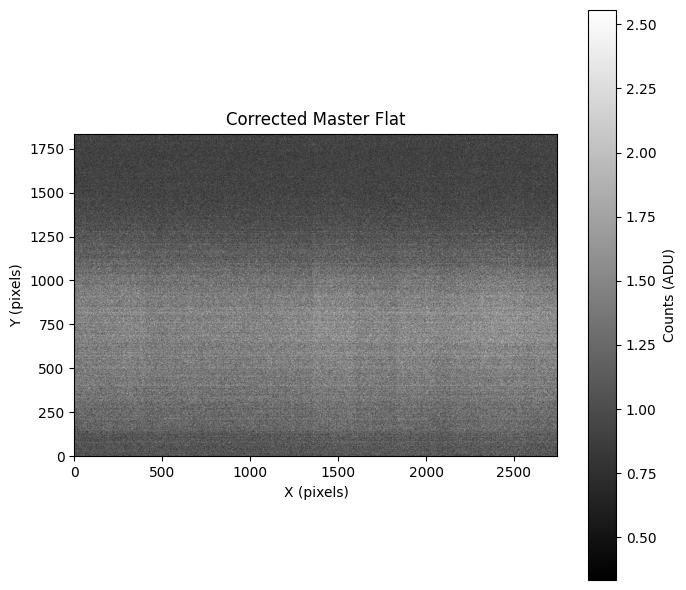

In [80]:
# 1. Scale the 60s dark frame to match the 10s flat frames exposure time
dark_scale_factor = 10.0 / 60.0
scaled_dark_for_flat = master_dark_corrected * dark_scale_factor

normalized_flats_corrected = []
for f in flat_files:
    # Subtract both master bias and the scaled dark current
    flat_corrected = fits.getdata(f).astype(np.float32) - master_bias - scaled_dark_for_flat

    # Normalize using the same crop region
    flat_corrected_cropped = flat_corrected
    norm_factor = np.median(flat_corrected_cropped)

    # Prevent division by zero if norm_factor is somehow zero
    if norm_factor == 0:
        norm_factor = 1.0

    normalized_flats_corrected.append(flat_corrected / norm_factor)

# Create the corrected master flat
master_flat_corrected = np.median(normalized_flats_corrected, axis=0)

# Avoid division by zero in final correction: set any extremely small flat values to 1.0
master_flat_corrected[master_flat_corrected < 0.01] = 1.0

fits.writeto(os.path.join(output_dir, 'master_flat_corrected.fits'), master_flat_corrected, overwrite=True)

display_fits(os.path.join(output_dir, 'master_flat_corrected.fits'), title='Corrected Master Flat')

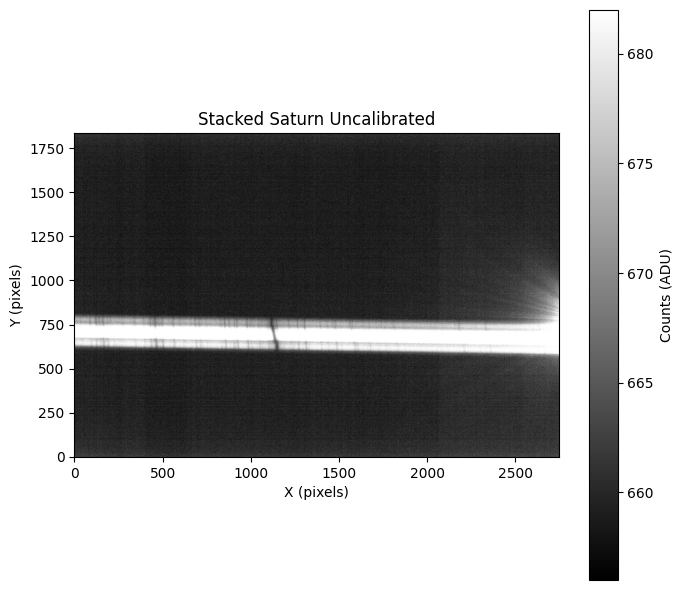

In [81]:
sci_stack = [fits.getdata(f) for f in saturn_files]
saturn_stacked = np.median(sci_stack, axis=0)
fits.writeto(os.path.join(output_dir, 'saturn_stacked_uncalibrated.fits'), saturn_stacked, overwrite=True)
display_fits(os.path.join(output_dir, 'saturn_stacked_uncalibrated.fits'), title='Stacked Saturn Uncalibrated')

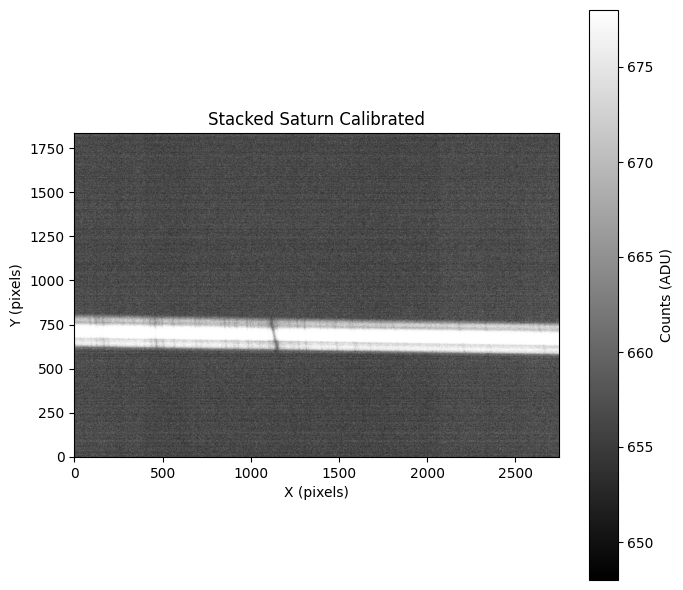

In [82]:
# Calibrate the stacked science frame using the fixed master flat
#calibrated_sci_stacked = (saturn_stacked - (master_bias) - (master_dark_corrected)) / master_flat_corrected
calibrated_sci_stacked = (saturn_stacked - (master_dark_corrected))
fits.writeto(os.path.join(output_dir, 'saturn_stacked_calibrated_0.fits'), calibrated_sci_stacked, overwrite=True)
display_fits(os.path.join(output_dir, 'saturn_stacked_calibrated_0.fits'), title='Stacked Saturn Calibrated')

--- Uncalibrated Stacked Saturn ---
Min: 630.00
Max: 13834.00
Mean: 662.31
Median: 660.00

--- Calibrated Stacked Saturn ---
Min: -284.00
Max: 11956.00
Mean: 659.03
Median: 656.00


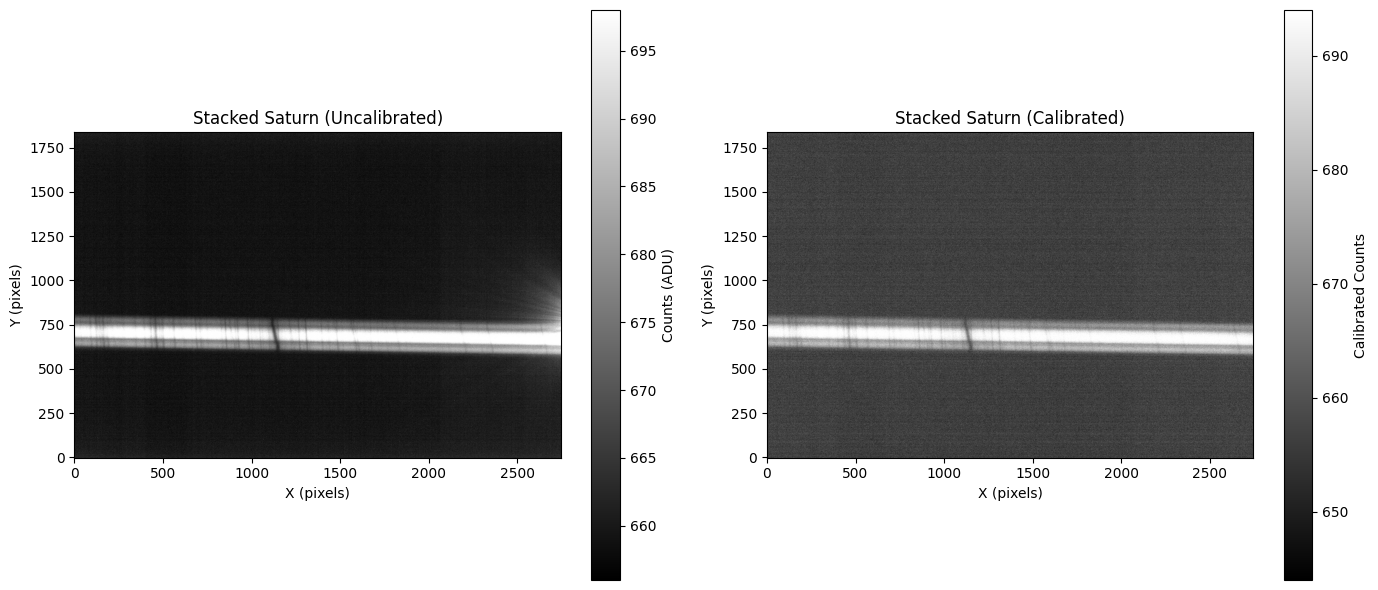

In [83]:
import numpy as np
import matplotlib.pyplot as plt

# Let's inspect some statistics of the uncalibrated vs calibrated data
print("--- Uncalibrated Stacked Saturn ---")
print(f"Min: {np.min(saturn_stacked):.2f}")
print(f"Max: {np.max(saturn_stacked):.2f}")
print(f"Mean: {np.mean(saturn_stacked):.2f}")
print(f"Median: {np.median(saturn_stacked):.2f}")

print("\n--- Calibrated Stacked Saturn ---")
print(f"Min: {np.min(calibrated_sci_stacked):.2f}")
print(f"Max: {np.max(calibrated_sci_stacked):.2f}")
print(f"Mean: {np.mean(calibrated_sci_stacked):.2f}")
print(f"Median: {np.median(calibrated_sci_stacked):.2f}")

# Plot both side-by-side to visually inspect the difference
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Dynamic range scaling based on 2nd and 98th percentiles for robust viewing
vmin_un, vmax_un = np.percentile(saturn_stacked, [2, 98])
im1 = axes[0].imshow(saturn_stacked, origin='lower', cmap='gray', vmin=vmin_un, vmax=vmax_un)
fig.colorbar(im1, ax=axes[0], label='Counts (ADU)')
axes[0].set_title('Stacked Saturn (Uncalibrated)')
axes[0].set_xlabel('X (pixels)')
axes[0].set_ylabel('Y (pixels)')

vmin_cal, vmax_cal = np.percentile(calibrated_sci_stacked, [2, 98])
im2 = axes[1].imshow(calibrated_sci_stacked, origin='lower', cmap='gray', vmin=vmin_cal, vmax=vmax_cal)
fig.colorbar(im2, ax=axes[1], label='Calibrated Counts')
axes[1].set_title('Stacked Saturn (Calibrated)')
axes[1].set_xlabel('X (pixels)')
axes[1].set_ylabel('Y (pixels)')

plt.tight_layout()
plt.show()

In [84]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

def normalize_spectroscopic_flat(flat_path, degree=7, dispersion_axis=1):
    """
    Normalize a 2D spectroscopic flat field by fitting and dividing out
    the low-frequency spectral response (blaze/lamp SED) along the dispersion axis.

    Parameters:
    - flat_path (str): Path to the master flat FITS file.
    - degree (int): Degree of the polynomial fit along the dispersion axis.
    - dispersion_axis (int): Axis of dispersion (1 for horizontal/columns, 0 for vertical/rows).

    Returns:
    - raw_flat (numpy.ndarray): The input master flat data.
    - norm_flat (numpy.ndarray): The fully normalized flat field.
    """
    # 1. Load the master flat FITS data
    raw_flat = fits.getdata(flat_path).astype(float)
    norm_flat = np.empty_like(raw_flat)

    nrows, ncols = raw_flat.shape

    # 2. Fit and divide along the dispersion axis
    if dispersion_axis == 1:
        # Dispersion is horizontal (X-axis, columns)
        x = np.arange(ncols)
        for i in range(nrows):
            row = raw_flat[i, :]

            # Skip empty or dark rows outside the spatial trace/slit
            if np.sum(row) <= 0:
                norm_flat[i, :] = 1.0
                continue

            # Fit polynomial to the continuum/blaze function
            coeffs = np.polyfit(x, row, degree)
            fit_curve = np.polyval(coeffs, x)

            # Avoid division by zero or negative values
            fit_curve[fit_curve <= 0] = np.nan

            # Normalize the row to isolate pixel-to-pixel sensitivity
            norm_flat[i, :] = row / fit_curve

    else:
        # Dispersion is vertical (Y-axis, rows)
        y = np.arange(nrows)
        for j in range(ncols):
            col = raw_flat[:, j]

            if np.sum(col) <= 0:
                norm_flat[:, j] = 1.0
                continue

            coeffs = np.polyfit(y, col, degree)
            fit_curve = np.polyval(coeffs, y)
            fit_curve[fit_curve <= 0] = np.nan
            norm_flat[:, j] = col / fit_curve

    # Clean up any potential NaNs from empty regions
    norm_flat = np.nan_to_num(norm_flat, nan=1.0, posinf=1.0, neginf=1.0)

    return raw_flat, norm_flat

# --- Example Usage ---
# raw_flat, norm_flat = normalize_spectroscopic_flat('path_to_flat.fit', degree=9, dispersion_axis=1)